# Credit Scoring Capstone
## Notebook 03 — Stacking and Probability Calibration

This notebook develops the ensemble credit-scoring framework using
out-of-fold predictions from the selected base models.

### Objectives

- Reconstruct the training, validation, and test datasets
- Generate 5-fold out-of-fold predictions for the base learners
- Construct the meta-learning dataset
- Train a Meta-Logistic Regression model
- Evaluate the raw ensemble
- Apply Platt Scaling and Isotonic Regression
- Compare calibrated and uncalibrated probabilities
- Select the probability estimate used for financial analysis

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn

from pathlib import Path

from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    f1_score
)

from sklearn.linear_model import LogisticRegression

In [10]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.0+cpu
CUDA available: False


In [12]:
data_path = "../data/application_clean.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

Dataset shape: (307511, 125)


In [14]:
exclude_features = [
    "SK_ID_CURR",
    "TARGET",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

X = df.drop(
    columns=exclude_features
)

y = df["TARGET"]

In [16]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 121)
y shape: (307511,)


In [18]:
split_indices = pd.read_csv(
    "../data/split_indices.csv"
)

split_indices.head()

,index,split
0,163667,train
1,140470,train
2,91501,train
3,118815,train
4,99896,train


In [20]:
print(
    split_indices["split"].value_counts()
)

print(
    "Unique indices:",
    split_indices["index"].nunique()
)

split
train         215257
validation     46127
test           46127
Name: count, dtype: int64
Unique indices: 307511


In [22]:
train_idx = split_indices.loc[
    split_indices["split"] == "train",
    "index"
].values

val_idx = split_indices.loc[
    split_indices["split"] == "validation",
    "index"
].values

test_idx = split_indices.loc[
    split_indices["split"] == "test",
    "index"
].values

In [24]:
X_train = X.loc[train_idx].copy()
y_train = y.loc[train_idx].copy()

X_val = X.loc[val_idx].copy()
y_val = y.loc[val_idx].copy()

X_test = X.loc[test_idx].copy()
y_test = y.loc[test_idx].copy()

In [26]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nDefault rates:")
print("Training:", y_train.mean())
print("Validation:", y_val.mean())
print("Test:", y_test.mean())

Training: (215257, 121)
Validation: (46127, 121)
Test: (46127, 121)

Default rates:
Training: 0.08072675917624049
Validation: 0.08073362672621241
Test: 0.08073362672621241


### Data-Split Design

The original train-validation-test partition from Notebook 02 is reused.

The training set is used to generate out-of-fold predictions and train the
stacking model.

The validation set is reserved for probability calibration.

The test set remains untouched until final evaluation of the raw and calibrated
ensemble probabilities.

In [28]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

C:\Users\USER\AppData\Local\Temp\ipykernel_8444\844720928.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [30]:
print(
    "Categorical:",
    len(categorical_cols)
)

print(
    "Numerical:",
    len(numerical_cols)
)

print(
    "Total:",
    len(categorical_cols) +
    len(numerical_cols)
)

Categorical: 16
Numerical: 105
Total: 121


In [32]:
baseline_lr = joblib.load(
    "../models/baseline_lr.joblib"
)

xgb_pipeline = joblib.load(
    "../models/xgb_pipeline.joblib"
)

In [34]:
mlp_preprocessor = joblib.load(
    "../models/mlp_preprocessor.joblib"
)

mlp_metadata = joblib.load(
    "../models/mlp_metadata.joblib"
)

In [36]:
print(
    "MLP input size:",
    mlp_metadata["input_size"]
)

MLP input size: 251


## 6. Out-of-Fold Predictions

The stacking model cannot be trained using predictions produced by base
models on observations that those same models were trained on.

Instead, 5-fold cross-validation is used to generate out-of-fold (OOF)
predictions.

For each fold:

1. Four folds are used to train the base model.
2. The remaining fold is predicted.
3. Predictions are stored for the held-out observations.
4. The process is repeated until every training observation has one
   out-of-fold prediction.

These predictions form the inputs to the Meta-Logistic Regression model.

In [38]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [40]:
lr_oof = np.zeros(
    len(X_train)
)

xgb_oof = np.zeros(
    len(X_train)
)

mlp_oof = np.zeros(
    len(X_train)
)

In [42]:
for fold, (train_pos, oof_pos) in enumerate(
    skf.split(X_train, y_train),
    start=1
):

    print(f"Fold {fold}/5")

    X_fold_train = X_train.iloc[
        train_pos
    ]

    y_fold_train = y_train.iloc[
        train_pos
    ]

    X_fold_oof = X_train.iloc[
        oof_pos
    ]

    fold_model = clone(
        baseline_lr
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    lr_oof[oof_pos] = (
        fold_model.predict_proba(
            X_fold_oof
        )[:, 1]
    )

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5


In [44]:
print(
    "Number of LR OOF predictions:",
    len(lr_oof)
)

print(
    "Minimum:",
    lr_oof.min()
)

print(
    "Maximum:",
    lr_oof.max()
)

print(
    "Mean:",
    lr_oof.mean()
)

Number of LR OOF predictions: 215257
Minimum: 2.3581630682052247e-10
Maximum: 0.7519847338112279
Mean: 0.08075411880788794


In [46]:
lr_oof_pred = (
    lr_oof >= 0.50
).astype(int)

lr_oof_roc = roc_auc_score(
    y_train,
    lr_oof
)

lr_oof_pr = average_precision_score(
    y_train,
    lr_oof
)

lr_oof_brier = brier_score_loss(
    y_train,
    lr_oof
)

lr_oof_f1 = f1_score(
    y_train,
    lr_oof_pred
)

print(f"OOF ROC-AUC: {lr_oof_roc:.4f}")
print(f"OOF PR-AUC:  {lr_oof_pr:.4f}")
print(f"OOF Brier:   {lr_oof_brier:.4f}")
print(f"OOF F1 @ 0.50: {lr_oof_f1:.4f}")

OOF ROC-AUC: 0.7435
OOF PR-AUC:  0.2175
OOF Brier:   0.0689
OOF F1 @ 0.50: 0.0220


## 10. XGBoost Out-of-Fold Predictions

Five-fold out-of-fold predictions are generated for XGBoost using the same
cross-validation structure as Logistic Regression.

For each fold, both the preprocessing pipeline and XGBoost model are fitted
using only the fold-training observations. Predictions are then generated for
the held-out fold.

This ensures that every OOF probability is generated by a model that did not
train on the corresponding observation.

In [48]:
for fold, (train_pos, oof_pos) in enumerate(
    skf.split(X_train, y_train),
    start=1
):

    print(f"Fold {fold}/5")

    X_fold_train = X_train.iloc[
        train_pos
    ]

    y_fold_train = y_train.iloc[
        train_pos
    ]

    X_fold_oof = X_train.iloc[
        oof_pos
    ]

    fold_model = clone(
        xgb_pipeline
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    xgb_oof[oof_pos] = (
        fold_model.predict_proba(
            X_fold_oof
        )[:, 1]
    )

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5


In [50]:
print(
    "Number of XGB OOF predictions:",
    len(xgb_oof)
)

print(
    "Minimum:",
    xgb_oof.min()
)

print(
    "Maximum:",
    xgb_oof.max()
)

print(
    "Mean:",
    xgb_oof.mean()
)

print(
    "Training default rate:",
    y_train.mean()
)

Number of XGB OOF predictions: 215257
Minimum: 0.0022261792328208685
Maximum: 0.7878032922744751
Mean: 0.08056125937374305
Training default rate: 0.08072675917624049


In [52]:
print(
    "Number of exact zero predictions:",
    np.sum(xgb_oof == 0)
)

Number of exact zero predictions: 0


In [54]:
xgb_oof_pred = (
    xgb_oof >= 0.50
).astype(int)

xgb_oof_roc = roc_auc_score(
    y_train,
    xgb_oof
)

xgb_oof_pr = average_precision_score(
    y_train,
    xgb_oof
)

xgb_oof_brier = brier_score_loss(
    y_train,
    xgb_oof
)

xgb_oof_f1 = f1_score(
    y_train,
    xgb_oof_pred
)

print(f"OOF ROC-AUC: {xgb_oof_roc:.4f}")
print(f"OOF PR-AUC:  {xgb_oof_pr:.4f}")
print(f"OOF Brier:   {xgb_oof_brier:.4f}")
print(f"OOF F1 @ 0.50: {xgb_oof_f1:.4f}")

OOF ROC-AUC: 0.7570
OOF PR-AUC:  0.2387
OOF Brier:   0.0680
OOF F1 @ 0.50: 0.0336


In [56]:
oof_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC_AUC": lr_oof_roc,
        "PR_AUC": lr_oof_pr,
        "Brier": lr_oof_brier,
        "F1_0.50": lr_oof_f1,
        "Mean_PD": lr_oof.mean()
    },
    {
        "Model": "XGBoost",
        "ROC_AUC": xgb_oof_roc,
        "PR_AUC": xgb_oof_pr,
        "Brier": xgb_oof_brier,
        "F1_0.50": xgb_oof_f1,
        "Mean_PD": xgb_oof.mean()
    }
])

oof_results.round(4)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Logistic Regression,0.7435,0.2175,0.0689,0.0220,0.0808
1,XGBoost,0.7570,0.2387,0.0680,0.0336,0.0806


In [58]:
lr_xgb_correlation = np.corrcoef(
    lr_oof,
    xgb_oof
)[0, 1]

print(
    "LR-XGBoost OOF probability correlation:",
    round(lr_xgb_correlation, 4)
)

LR-XGBoost OOF probability correlation: 0.9


### OOF Prediction Comparison

The out-of-fold probabilities represent predictions generated without
training on the corresponding observations.

Differences between the Logistic Regression and XGBoost OOF probabilities
indicate that the models capture somewhat different predictive relationships.
This diversity can potentially be exploited by the stacking model.

Prediction correlation is therefore examined as a descriptive measure of
model similarity, but lower correlation alone is not interpreted as evidence
of better model quality.

## 11. MLP Out-of-Fold Predictions

Five-fold out-of-fold (OOF) predictions are generated for the PyTorch
Multi-Layer Perceptron.

For each fold:

1. Four folds are used as the fold-training data.
2. The MLP preprocessing pipeline is fitted only on the fold-training data.
3. A new neural network is initialized and trained for 10 epochs.
4. Default probabilities are generated for the held-out fold.
5. The process is repeated until every training observation has one OOF
   probability.

This prevents both preprocessing and model-training leakage into the
out-of-fold predictions used by the stacking model.

In [79]:
from torch.utils.data import TensorDataset, DataLoader

class CreditMLP(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

The MLP architecture is kept identical to the base model developed in
Notebook 02:

**Input → 128 neurons → 64 neurons → 1 output**

ReLU activation is used in the hidden layers. The final layer returns a logit,
which is converted into a probability using the sigmoid function during
prediction.

In [82]:
mlp_oof = np.full(
    len(X_train),
    np.nan
)

mlp_fold_assignment = np.full(
    len(X_train),
    -1
)

In [84]:
num_epochs = 10
batch_size = 512
learning_rate = 0.001

print("Epochs:", num_epochs)
print("Batch size:", batch_size)
print("Learning rate:", learning_rate)

Epochs: 10
Batch size: 512
Learning rate: 0.001


The same MLP training configuration used in Notebook 02 is retained for
consistency. Each fold trains a fresh neural network for 10 epochs using
mini-batches of 512 observations and the Adam optimizer.

In [87]:
for fold, (train_pos, oof_pos) in enumerate(
    skf.split(X_train, y_train),
    start=1
):

    print("=" * 50)
    print(f"MLP Fold {fold}/5")
    print("=" * 50)

    # ---------------------------------------
    # 1. Create fold train and held-out data
    # ---------------------------------------

    X_fold_train = X_train.iloc[train_pos]
    y_fold_train = y_train.iloc[train_pos]

    X_fold_oof = X_train.iloc[oof_pos]

    # ---------------------------------------
    # 2. Fit preprocessing on fold train only
    # ---------------------------------------

    fold_preprocessor = clone(
        mlp_preprocessor
    )

    X_fold_train_processed = (
        fold_preprocessor.fit_transform(
            X_fold_train
        )
    )

    X_fold_oof_processed = (
        fold_preprocessor.transform(
            X_fold_oof
        )
    )

    # ---------------------------------------
    # 3. Convert training data to tensors
    # ---------------------------------------

    X_fold_train_tensor = torch.tensor(
        X_fold_train_processed,
        dtype=torch.float32
    )

    y_fold_train_tensor = torch.tensor(
        y_fold_train.values,
        dtype=torch.float32
    ).reshape(-1, 1)

    X_fold_oof_tensor = torch.tensor(
        X_fold_oof_processed,
        dtype=torch.float32
    )

    # ---------------------------------------
    # 4. Create mini-batches
    # ---------------------------------------

    fold_dataset = TensorDataset(
        X_fold_train_tensor,
        y_fold_train_tensor
    )

    fold_loader = DataLoader(
        fold_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    # ---------------------------------------
    # 5. Initialize a fresh neural network
    # ---------------------------------------

    torch.manual_seed(42 + fold)

    fold_model = CreditMLP(
        input_size=X_fold_train_tensor.shape[1]
    )

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        fold_model.parameters(),
        lr=learning_rate
    )

    # ---------------------------------------
    # 6. Train the neural network
    # ---------------------------------------

    for epoch in range(num_epochs):

        fold_model.train()

        total_loss = 0.0

        for X_batch, y_batch in fold_loader:

            optimizer.zero_grad()

            logits = fold_model(
                X_batch
            )

            loss = criterion(
                logits,
                y_batch
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item()
                * X_batch.size(0)
            )

        epoch_loss = (
            total_loss
            / len(fold_dataset)
        )

        print(
            f"Epoch {epoch + 1:02d}/{num_epochs} "
            f"- Loss: {epoch_loss:.4f}"
        )

    # ---------------------------------------
    # 7. Generate held-out probabilities
    # ---------------------------------------

    fold_model.eval()

    with torch.no_grad():

        fold_logits = fold_model(
            X_fold_oof_tensor
        )

        fold_probabilities = (
            torch.sigmoid(fold_logits)
            .cpu()
            .numpy()
            .ravel()
        )

    # ---------------------------------------
    # 8. Store OOF predictions
    # ---------------------------------------

    mlp_oof[oof_pos] = (
        fold_probabilities
    )

    mlp_fold_assignment[oof_pos] = fold

    print(f"Fold {fold} completed.")

MLP Fold 1/5
Epoch 01/10 - Loss: 0.2727
Epoch 02/10 - Loss: 0.2514
Epoch 03/10 - Loss: 0.2500
Epoch 04/10 - Loss: 0.2489
Epoch 05/10 - Loss: 0.2474
Epoch 06/10 - Loss: 0.2458
Epoch 07/10 - Loss: 0.2438
Epoch 08/10 - Loss: 0.2420
Epoch 09/10 - Loss: 0.2400
Epoch 10/10 - Loss: 0.2379
Fold 1 completed.
MLP Fold 2/5
Epoch 01/10 - Loss: 0.2699
Epoch 02/10 - Loss: 0.2506
Epoch 03/10 - Loss: 0.2494
Epoch 04/10 - Loss: 0.2481
Epoch 05/10 - Loss: 0.2466
Epoch 06/10 - Loss: 0.2447
Epoch 07/10 - Loss: 0.2429
Epoch 08/10 - Loss: 0.2410
Epoch 09/10 - Loss: 0.2387
Epoch 10/10 - Loss: 0.2369
Fold 2 completed.
MLP Fold 3/5
Epoch 01/10 - Loss: 0.2690
Epoch 02/10 - Loss: 0.2509
Epoch 03/10 - Loss: 0.2496
Epoch 04/10 - Loss: 0.2481
Epoch 05/10 - Loss: 0.2464
Epoch 06/10 - Loss: 0.2446
Epoch 07/10 - Loss: 0.2428
Epoch 08/10 - Loss: 0.2408
Epoch 09/10 - Loss: 0.2390
Epoch 10/10 - Loss: 0.2367
Fold 3 completed.
MLP Fold 4/5
Epoch 01/10 - Loss: 0.2697
Epoch 02/10 - Loss: 0.2512
Epoch 03/10 - Loss: 0.2500
Epo

In [89]:
print(
    "Number of predictions:",
    len(mlp_oof)
)

print(
    "Missing OOF predictions:",
    np.isnan(mlp_oof).sum()
)

print(
    "Unassigned observations:",
    np.sum(mlp_fold_assignment == -1)
)

print(
    "Minimum probability:",
    np.nanmin(mlp_oof)
)

print(
    "Maximum probability:",
    np.nanmax(mlp_oof)
)

print(
    "Mean probability:",
    np.nanmean(mlp_oof)
)

print(
    "Training default rate:",
    y_train.mean()
)

Number of predictions: 215257
Missing OOF predictions: 0
Unassigned observations: 0
Minimum probability: 0.0
Maximum probability: 0.9405409693717957
Mean probability: 0.07855906659728792
Training default rate: 0.08072675917624049


In [91]:
mlp_oof_pred = (
    mlp_oof >= 0.50
).astype(int)

mlp_oof_roc = roc_auc_score(
    y_train,
    mlp_oof
)

mlp_oof_pr = average_precision_score(
    y_train,
    mlp_oof
)

mlp_oof_brier = brier_score_loss(
    y_train,
    mlp_oof
)

mlp_oof_f1 = f1_score(
    y_train,
    mlp_oof_pred
)

print(f"OOF ROC-AUC: {mlp_oof_roc:.4f}")
print(f"OOF PR-AUC:  {mlp_oof_pr:.4f}")
print(f"OOF Brier:   {mlp_oof_brier:.4f}")
print(f"OOF F1 @ 0.50: {mlp_oof_f1:.4f}")

OOF ROC-AUC: 0.7270
OOF PR-AUC:  0.2021
OOF Brier:   0.0700
OOF F1 @ 0.50: 0.0336


### MLP OOF Results

The MLP achieved an OOF ROC-AUC of approximately 0.727 and PR-AUC of
approximately 0.202.

Its mean predicted probability was approximately 0.079, compared with an
observed training default rate of approximately 0.081.

The MLP provides the third probability signal used by the stacking framework.
Its contribution to the final ensemble will be determined by the
Meta-Logistic Regression rather than by its standalone performance alone.

In [95]:
oof_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC_AUC": lr_oof_roc,
        "PR_AUC": lr_oof_pr,
        "Brier": lr_oof_brier,
        "F1_0.50": lr_oof_f1,
        "Mean_PD": lr_oof.mean()
    },
    {
        "Model": "XGBoost",
        "ROC_AUC": xgb_oof_roc,
        "PR_AUC": xgb_oof_pr,
        "Brier": xgb_oof_brier,
        "F1_0.50": xgb_oof_f1,
        "Mean_PD": xgb_oof.mean()
    },
    {
        "Model": "PyTorch MLP",
        "ROC_AUC": mlp_oof_roc,
        "PR_AUC": mlp_oof_pr,
        "Brier": mlp_oof_brier,
        "F1_0.50": mlp_oof_f1,
        "Mean_PD": mlp_oof.mean()
    }
])

oof_results.round(4)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Logistic Regression,0.7435,0.2175,0.0689,0.0220,0.0808
1,XGBoost,0.7570,0.2387,0.0680,0.0336,0.0806
2,PyTorch MLP,0.7270,0.2021,0.0700,0.0336,0.0786


In [97]:
oof_probability_df = pd.DataFrame({
    "Logistic Regression": lr_oof,
    "XGBoost": xgb_oof,
    "MLP": mlp_oof
})

oof_correlation = (
    oof_probability_df
    .corr()
    .round(4)
)

oof_correlation

,Logistic Regression,XGBoost,MLP
Logistic Regression,1.0000,0.9000,0.8329
XGBoost,0.9000,1.0000,0.8233
MLP,0.8329,0.8233,1.0000


### Prediction Diversity

Correlation between the OOF probabilities is examined to understand the
similarity of the three base learners.

The purpose of stacking is not simply to combine the three highest-performing
models. The meta-model may benefit when the base learners capture different
predictive relationships.

However, lower correlation alone does not imply that a model is useful.
Individual predictive performance and complementary information must both be
considered.

In [100]:
oof_predictions = pd.DataFrame({
    "index": X_train.index,
    "y_true": y_train.values,
    "lr_oof": lr_oof,
    "xgb_oof": xgb_oof,
    "mlp_oof": mlp_oof
})

oof_predictions.to_csv(
    "../outputs/oof_predictions.csv",
    index=False
)

oof_results.to_csv(
    "../outputs/oof_model_results.csv",
    index=False
)

print(
    "OOF predictions saved:",
    oof_predictions.shape
)

print(
    "OOF results saved:",
    oof_results.shape
)

OOF predictions saved: (215257, 5)
OOF results saved: (3, 6)


## 12. Meta-Learning Dataset

The out-of-fold probabilities generated by Logistic Regression, XGBoost,
and the PyTorch MLP are combined to construct the meta-learning dataset.

Each training observation is represented by three probability features:

- Logistic Regression OOF probability
- XGBoost OOF probability
- MLP OOF probability

These probabilities were generated while each observation was held out from
the corresponding base-model training process. Therefore, they can be used
as inputs to the stacking model while reducing base-model training leakage.

In [103]:
X_meta_train = np.column_stack([
    lr_oof,
    xgb_oof,
    mlp_oof
])

y_meta_train = y_train.values

print(
    "Meta training shape:",
    X_meta_train.shape
)

print(
    "Meta target shape:",
    y_meta_train.shape
)

Meta training shape: (215257, 3)
Meta target shape: (215257,)


In [105]:
meta_train_df = pd.DataFrame(
    X_meta_train,
    columns=[
        "LR_PD",
        "XGB_PD",
        "MLP_PD"
    ],
    index=X_train.index
)

meta_train_df["TARGET"] = y_meta_train

meta_train_df.head()

,LR_PD,XGB_PD,MLP_PD,TARGET
163667,0.030935,0.039850,0.034389,0
140470,0.036264,0.023131,0.026681,0
91501,0.047972,0.100093,0.061094,1
118815,0.061456,0.038626,0.024597,0
99896,0.133843,0.102260,0.186416,0


In [107]:
meta_train_df.describe().round(4)

,LR_PD,XGB_PD,MLP_PD,TARGET
count,215257.0000,215257.0000,215257.0000,215257.0000
mean,0.0808,0.0806,0.0786,0.0807
std,0.0759,0.0792,0.0854,0.2724
min,0.0000,0.0022,0.0000,0.0000
25%,0.0311,0.0291,0.0225,0.0000
50%,0.0561,0.0535,0.0492,0.0000
75%,0.1027,0.1025,0.1022,0.0000
max,0.7520,0.7878,0.9405,1.0000


## 13. Meta-Logistic Regression

Logistic Regression is used as the meta-learner in the stacking framework.

Rather than using the original borrower characteristics directly, the
meta-model receives the three out-of-fold probability estimates produced
by the base learners.

The meta-model learns how these probability signals should be combined to
produce the ensemble's raw probability of default.

In [110]:
meta_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

meta_model.fit(
    X_meta_train,
    y_meta_train
)

print("Meta-model training completed.")

Meta-model training completed.


In [112]:
meta_coefficients = pd.DataFrame({
    "Base_Model": [
        "Logistic Regression",
        "XGBoost",
        "MLP"
    ],
    "Coefficient": meta_model.coef_[0]
})

print(
    "Intercept:",
    meta_model.intercept_[0]
)

meta_coefficients

Intercept: -3.3619110104708336


,Base_Model,Coefficient
0,Logistic Regression,2.374328
1,XGBoost,6.005587
2,MLP,0.448879


In [114]:
meta_train_prob = meta_model.predict_proba(
    X_meta_train
)[:, 1]

meta_train_pred = (
    meta_train_prob >= 0.50
).astype(int)

In [116]:
print(
    "Minimum raw PD:",
    meta_train_prob.min()
)

print(
    "Maximum raw PD:",
    meta_train_prob.max()
)

print(
    "Mean raw PD:",
    meta_train_prob.mean()
)

print(
    "Observed default rate:",
    y_meta_train.mean()
)

Minimum raw PD: 0.034040957829408566
Maximum raw PD: 0.9472801413915198
Mean raw PD: 0.08075573115005123
Observed default rate: 0.08072675917624049


In [118]:
meta_train_roc = roc_auc_score(
    y_meta_train,
    meta_train_prob
)

meta_train_pr = average_precision_score(
    y_meta_train,
    meta_train_prob
)

meta_train_brier = brier_score_loss(
    y_meta_train,
    meta_train_prob
)

meta_train_f1 = f1_score(
    y_meta_train,
    meta_train_pred
)

print(f"Meta ROC-AUC:      {meta_train_roc:.4f}")
print(f"Meta PR-AUC:       {meta_train_pr:.4f}")
print(f"Meta Brier:        {meta_train_brier:.4f}")
print(f"Meta F1 @ 0.50:    {meta_train_f1:.4f}")
print(f"Meta Mean PD:      {meta_train_prob.mean():.4f}")

Meta ROC-AUC:      0.7569
Meta PR-AUC:       0.2380
Meta Brier:        0.0689
Meta F1 @ 0.50:    0.0956
Meta Mean PD:      0.0808


In [120]:
joblib.dump(
    meta_model,
    "../models/meta_logistic.joblib"
)

meta_train_df.to_csv(
    "../outputs/meta_training_data.csv"
)

print(
    "Meta-Logistic Regression and "
    "meta-training data saved."
)

Meta-Logistic Regression and meta-training data saved.


## 14. Validation Predictions for the Stacking Model

The trained stacking framework is now evaluated on the validation set.

The selected base models generate probability-of-default estimates for each
validation applicant. These three probabilities are then supplied to the
Meta-Logistic Regression to obtain the ensemble's raw probability of default.

The validation set was not used to train the base models or the meta-model.
It will subsequently be used to fit and compare probability calibration
methods.

In [123]:
val_predictions = pd.read_csv(
    "../outputs/base_validation_predictions.csv"
)

print(
    "Saved validation predictions:",
    val_predictions.shape
)

val_predictions.head()

Saved validation predictions: (46127, 5)


,index,y_true,lr_probability,xgb_probability,mlp_probability
0,266395,0,0.147797,0.156580,0.186267
1,190842,0,0.029587,0.026750,0.025477
2,152795,0,0.049784,0.042667,0.100005
3,45638,0,0.177394,0.118846,0.237831
4,272293,0,0.029363,0.043425,0.032698


In [125]:
val_predictions = (
    val_predictions
    .set_index("index")
    .loc[X_val.index]
)

print(
    "Aligned validation predictions:",
    val_predictions.shape
)

Aligned validation predictions: (46127, 4)


In [127]:
target_match = np.array_equal(
    val_predictions["y_true"].values,
    y_val.values
)

print(
    "Validation targets aligned:",
    target_match
)

Validation targets aligned: True


In [129]:
print(
    "Missing values:",
    val_predictions[
        [
            "lr_probability",
            "xgb_probability",
            "mlp_probability"
        ]
    ].isna().sum()
)

Missing values: lr_probability     0
xgb_probability    0
mlp_probability    0
dtype: int64


In [131]:
lr_val_prob = (
    val_predictions[
        "lr_probability"
    ].values
)

xgb_val_prob = (
    val_predictions[
        "xgb_probability"
    ].values
)

mlp_val_prob = (
    val_predictions[
        "mlp_probability"
    ].values
)

In [133]:
X_meta_val = np.column_stack([
    lr_val_prob,
    xgb_val_prob,
    mlp_val_prob
])

print(
    "Validation meta shape:",
    X_meta_val.shape
)

Validation meta shape: (46127, 3)


In [135]:
meta_val_prob = (
    meta_model.predict_proba(
        X_meta_val
    )[:, 1]
)

meta_val_pred = (
    meta_val_prob >= 0.50
).astype(int)

In [137]:
print(
    "Minimum raw ensemble PD:",
    meta_val_prob.min()
)

print(
    "Maximum raw ensemble PD:",
    meta_val_prob.max()
)

print(
    "Mean raw ensemble PD:",
    meta_val_prob.mean()
)

print(
    "Validation default rate:",
    y_val.mean()
)

Minimum raw ensemble PD: 0.03435929454060207
Maximum raw ensemble PD: 0.9183122469757046
Mean raw ensemble PD: 0.0808367176938841
Validation default rate: 0.08073362672621241


In [139]:
meta_val_roc = roc_auc_score(
    y_val,
    meta_val_prob
)

meta_val_pr = average_precision_score(
    y_val,
    meta_val_prob
)

meta_val_brier = brier_score_loss(
    y_val,
    meta_val_prob
)

meta_val_f1 = f1_score(
    y_val,
    meta_val_pred
)

print(f"Raw Ensemble ROC-AUC: {meta_val_roc:.4f}")
print(f"Raw Ensemble PR-AUC:  {meta_val_pr:.4f}")
print(f"Raw Ensemble Brier:   {meta_val_brier:.4f}")
print(f"Raw Ensemble F1 @ 0.50: {meta_val_f1:.4f}")
print(f"Raw Ensemble Mean PD: {meta_val_prob.mean():.4f}")

Raw Ensemble ROC-AUC: 0.7636
Raw Ensemble PR-AUC:  0.2549
Raw Ensemble Brier:   0.0680
Raw Ensemble F1 @ 0.50: 0.1105
Raw Ensemble Mean PD: 0.0808


In [141]:
validation_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC_AUC": roc_auc_score(
            y_val,
            lr_val_prob
        ),
        "PR_AUC": average_precision_score(
            y_val,
            lr_val_prob
        ),
        "Brier": brier_score_loss(
            y_val,
            lr_val_prob
        ),
        "F1_0.50": f1_score(
            y_val,
            (lr_val_prob >= 0.50).astype(int)
        ),
        "Mean_PD": lr_val_prob.mean()
    },

    {
        "Model": "XGBoost",
        "ROC_AUC": roc_auc_score(
            y_val,
            xgb_val_prob
        ),
        "PR_AUC": average_precision_score(
            y_val,
            xgb_val_prob
        ),
        "Brier": brier_score_loss(
            y_val,
            xgb_val_prob
        ),
        "F1_0.50": f1_score(
            y_val,
            (xgb_val_prob >= 0.50).astype(int)
        ),
        "Mean_PD": xgb_val_prob.mean()
    },

    {
        "Model": "PyTorch MLP",
        "ROC_AUC": roc_auc_score(
            y_val,
            mlp_val_prob
        ),
        "PR_AUC": average_precision_score(
            y_val,
            mlp_val_prob
        ),
        "Brier": brier_score_loss(
            y_val,
            mlp_val_prob
        ),
        "F1_0.50": f1_score(
            y_val,
            (mlp_val_prob >= 0.50).astype(int)
        ),
        "Mean_PD": mlp_val_prob.mean()
    },

    {
        "Model": "Raw Ensemble",
        "ROC_AUC": meta_val_roc,
        "PR_AUC": meta_val_pr,
        "Brier": meta_val_brier,
        "F1_0.50": meta_val_f1,
        "Mean_PD": meta_val_prob.mean()
    }
])

validation_comparison.round(4)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Logistic Regression,0.7515,0.2342,0.0683,0.0283,0.0809
1,XGBoost,0.7625,0.2543,0.0675,0.0384,0.0806
2,PyTorch MLP,0.7416,0.2147,0.0692,0.0215,0.0788
3,Raw Ensemble,0.7636,0.2549,0.0680,0.1105,0.0808


In [143]:
ensemble_validation_predictions = pd.DataFrame({
    "index": X_val.index,
    "y_true": y_val.values,
    "lr_probability": lr_val_prob,
    "xgb_probability": xgb_val_prob,
    "mlp_probability": mlp_val_prob,
    "raw_ensemble_probability": meta_val_prob
})

ensemble_validation_predictions.to_csv(
    "../outputs/ensemble_validation_predictions.csv",
    index=False
)

validation_comparison.to_csv(
    "../outputs/validation_model_comparison.csv",
    index=False
)

print(
    "Validation ensemble predictions saved:",
    ensemble_validation_predictions.shape
)

Validation ensemble predictions saved: (46127, 6)


### Validation Ensemble

The three base-model probability estimates were combined using the trained
Meta-Logistic Regression to produce a raw ensemble probability of default.

Performance on the validation set provides an independent assessment of the
stacking model relative to the individual base learners.

The raw ensemble probabilities have not yet undergone an additional
probability-calibration procedure. The next stage therefore evaluates
Platt Scaling and Isotonic Regression as calibration methods.

## 15. Probability Calibration

The raw probabilities produced by the stacking model are subsequently
calibrated.

Probability calibration is important in credit-risk modelling because the
predicted probability is used as an estimate of Probability of Default (PD).
A model may discriminate effectively between lower-risk and higher-risk
borrowers while still producing probabilities that do not accurately
represent observed default frequencies.

Two calibration approaches are evaluated:

1. Platt Scaling
2. Isotonic Regression

Both calibration models are fitted using the validation set. Their final
performance will later be assessed on the untouched test set.

### 15.1 Platt Scaling

Platt Scaling applies a logistic transformation to the raw ensemble
probabilities.

The raw probabilities are first converted to log-odds. Logistic Regression
is then fitted using the validation outcomes to learn a calibrated mapping
between the ensemble output and the observed default outcome.

Platt Scaling provides a smooth parametric calibration function.

In [148]:
eps = 1e-6

meta_val_clipped = np.clip(
    meta_val_prob,
    eps,
    1 - eps
)

meta_val_logit = np.log(
    meta_val_clipped /
    (1 - meta_val_clipped)
).reshape(-1, 1)

In [150]:
platt_calibrator = LogisticRegression(
    random_state=42
)

platt_calibrator.fit(
    meta_val_logit,
    y_val
)

print(
    "Platt intercept:",
    platt_calibrator.intercept_[0]
)

print(
    "Platt coefficient:",
    platt_calibrator.coef_[0][0]
)

Platt intercept: 0.10533721947344478
Platt coefficient: 1.048056526960937


In [152]:
platt_val_prob = (
    platt_calibrator.predict_proba(
        meta_val_logit
    )[:, 1]
)

print(
    "Raw ensemble mean PD:",
    meta_val_prob.mean()
)

print(
    "Platt mean PD:",
    platt_val_prob.mean()
)

print(
    "Observed default rate:",
    y_val.mean()
)

Raw ensemble mean PD: 0.0808367176938841
Platt mean PD: 0.08073095218071913
Observed default rate: 0.08073362672621241


### 15.2 Isotonic Regression

Isotonic Regression provides a non-parametric calibration approach.

Unlike Platt Scaling, it does not assume that the calibration relationship
follows a logistic functional form. Instead, it learns a monotonically
increasing mapping between the raw ensemble probabilities and observed
default outcomes.

This provides greater flexibility but can also make the calibration mapping
more sensitive to the available calibration data.

In [155]:
from sklearn.isotonic import IsotonicRegression

isotonic_calibrator = IsotonicRegression(
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    meta_val_prob,
    y_val
)

,"out_of_bounds out_of_bounds: {'nan', 'clip', 'raise'}, default='nan'Handles how `X` values outside of the training domain are handledduring prediction.- 'nan', predictions will be NaN.- 'clip', predictions will be set to the value corresponding to the nearest train interval endpoint.- 'raise', a `ValueError` is raised.",'clip'
,"y_min y_min: float, default=NoneLower bound on the lowest predicted value (the minimum value maystill be higher). If not set, defaults to -inf.",None
,"y_max y_max: float, default=NoneUpper bound on the highest predicted value (the maximum may still belower). If not set, defaults to +inf.",None
,"increasing increasing: bool or 'auto', default=TrueDetermines whether the predictions should be constrained to increaseor decrease with `X`. 'auto' will decide based on the Spearmancorrelation estimate's sign.",True
Name,Type,Value
X_max_ X_max_: floatMaximum value of input array `X_` for right bound.,float64,0.9183
X_min_ X_min_: floatMinimum value of input array `X_` for left bound.,float64,0.03436
"X_thresholds_ X_thresholds_: ndarray of shape (n_thresholds,)Unique ascending `X` values used to interpolatethe y = f(X) monotonic function... versionadded:: 0.24","ndarray[float64](120,)","[0.03,0.04,0.04,...,0.87,0.88,0.92]"
f_ f_: functionThe stepwise interpolating function that covers the input domain ``X``.,interp1d,<scipy.interp...0016681AECFA0>
increasing_ increasing_: boolInferred value for ``increasing``.,bool,True
"y_thresholds_ y_thresholds_: ndarray of shape (n_thresholds,)De-duplicated `y` values suitable to interpolate the y = f(X)monotonic function... versionadded:: 0.24","ndarray[float64](120,)","[0. ,0. ,0.01,...,0.8 ,0.81,0.81]"


In [157]:
isotonic_val_prob = (
    isotonic_calibrator.predict(
        meta_val_prob
    )
)

In [159]:
print(
    "Raw ensemble mean PD:",
    meta_val_prob.mean()
)

print(
    "Platt mean PD:",
    platt_val_prob.mean()
)

print(
    "Isotonic mean PD:",
    isotonic_val_prob.mean()
)

print(
    "Observed default rate:",
    y_val.mean()
)

Raw ensemble mean PD: 0.0808367176938841
Platt mean PD: 0.08073095218071913
Isotonic mean PD: 0.08073362672621241
Observed default rate: 0.08073362672621241


In [161]:
joblib.dump(
    platt_calibrator,
    "../models/platt_calibrator.joblib"
)

joblib.dump(
    isotonic_calibrator,
    "../models/isotonic_calibrator.joblib"
)

print(
    "Calibration models saved."
)

Calibration models saved.


In [163]:
calibration_validation_predictions = pd.DataFrame({
    "index": X_val.index,
    "y_true": y_val.values,
    "raw_ensemble_probability": meta_val_prob,
    "platt_probability": platt_val_prob,
    "isotonic_probability": isotonic_val_prob
})

calibration_validation_predictions.to_csv(
    "../outputs/calibration_validation_predictions.csv",
    index=False
)

print(
    "Calibration validation predictions saved:",
    calibration_validation_predictions.shape
)

Calibration validation predictions saved: (46127, 5)


## 16. Final Evaluation on the Test Set

The untouched test set is used for the final evaluation of the stacking and
calibration framework.

The test observations were not used to train the base models, train the
Meta-Logistic Regression, or fit the probability calibration models.

The three base models first generate probability estimates for each test
applicant. These probabilities are combined by the Meta-Logistic Regression
to obtain the raw ensemble PD. Platt Scaling and Isotonic Regression are then
applied to obtain calibrated PD estimates.

In [166]:
lr_test_prob = (
    baseline_lr.predict_proba(
        X_test
    )[:, 1]
)

xgb_test_prob = (
    xgb_pipeline.predict_proba(
        X_test
    )[:, 1]
)

print(
    "LR test predictions:",
    len(lr_test_prob)
)

print(
    "XGB test predictions:",
    len(xgb_test_prob)
)

LR test predictions: 46127
XGB test predictions: 46127


In [168]:
mlp_metadata = joblib.load(
    "../models/mlp_metadata.joblib"
)

mlp_metadata

{'input_size': 251,
 'hidden_layer_1': 128,
 'hidden_layer_2': 64,
 'output_size': 1}

In [170]:
final_mlp = CreditMLP(
    input_size=mlp_metadata["input_size"]
)

In [172]:
final_mlp.load_state_dict(
    torch.load(
        "../models/mlp_state_dict.pt",
        map_location="cpu"
    )
)

final_mlp.eval()

print("Final MLP loaded.")

Final MLP loaded.


In [174]:
X_test_mlp = (
    mlp_preprocessor.transform(
        X_test
    )
)

print(
    "Processed MLP test shape:",
    X_test_mlp.shape
)

Processed MLP test shape: (46127, 251)


In [176]:
X_test_mlp_tensor = torch.tensor(
    X_test_mlp,
    dtype=torch.float32
)

In [178]:
with torch.no_grad():

    mlp_test_logits = final_mlp(
        X_test_mlp_tensor
    )

    mlp_test_prob = (
        torch.sigmoid(
            mlp_test_logits
        )
        .cpu()
        .numpy()
        .ravel()
    )

print(
    "MLP test predictions:",
    len(mlp_test_prob)
)

print(
    "MLP mean test PD:",
    mlp_test_prob.mean()
)

MLP test predictions: 46127
MLP mean test PD: 0.07857084


In [180]:
X_meta_test = np.column_stack([
    lr_test_prob,
    xgb_test_prob,
    mlp_test_prob
])

print(
    "Test meta shape:",
    X_meta_test.shape
)

Test meta shape: (46127, 3)


In [182]:
meta_test_prob = (
    meta_model.predict_proba(
        X_meta_test
    )[:, 1]
)

print(
    "Raw ensemble mean PD:",
    meta_test_prob.mean()
)

print(
    "Actual test default rate:",
    y_test.mean()
)

Raw ensemble mean PD: 0.08098500730756522
Actual test default rate: 0.08073362672621241


In [184]:
meta_test_clipped = np.clip(
    meta_test_prob,
    eps,
    1 - eps
)

meta_test_logit = np.log(
    meta_test_clipped /
    (1 - meta_test_clipped)
).reshape(-1, 1)

In [186]:
platt_test_prob = (
    platt_calibrator.predict_proba(
        meta_test_logit
    )[:, 1]
)

In [188]:
isotonic_test_prob = (
    isotonic_calibrator.predict(
        meta_test_prob
    )
)

In [190]:
print(
    "Actual default rate:",
    y_test.mean()
)

print(
    "Raw mean PD:",
    meta_test_prob.mean()
)

print(
    "Platt mean PD:",
    platt_test_prob.mean()
)

print(
    "Isotonic mean PD:",
    isotonic_test_prob.mean()
)

Actual default rate: 0.08073362672621241
Raw mean PD: 0.08098500730756522
Platt mean PD: 0.08089330867556127
Isotonic mean PD: 0.08088402857465689


In [192]:
def evaluate_probability_model(
    name,
    y_true,
    probability
):

    prediction = (
        probability >= 0.50
    ).astype(int)

    return {
        "Model": name,

        "ROC_AUC": roc_auc_score(
            y_true,
            probability
        ),

        "PR_AUC": average_precision_score(
            y_true,
            probability
        ),

        "Brier": brier_score_loss(
            y_true,
            probability
        ),

        "F1_0.50": f1_score(
            y_true,
            prediction
        ),

        "Mean_PD": probability.mean()
    }

In [194]:
final_test_results = pd.DataFrame([
    evaluate_probability_model(
        "Raw Ensemble",
        y_test,
        meta_test_prob
    ),

    evaluate_probability_model(
        "Platt",
        y_test,
        platt_test_prob
    ),

    evaluate_probability_model(
        "Isotonic",
        y_test,
        isotonic_test_prob
    )
])

final_test_results.round(4)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Raw Ensemble,0.7627,0.2517,0.0682,0.1003,0.0810
1,Platt,0.7627,0.2517,0.0683,0.1100,0.0809
2,Isotonic,0.7618,0.2425,0.0675,0.0283,0.0809


In [196]:
final_test_predictions = pd.DataFrame({
    "index": X_test.index,
    "y_true": y_test.values,

    "lr_probability": lr_test_prob,
    "xgb_probability": xgb_test_prob,
    "mlp_probability": mlp_test_prob,

    "raw_ensemble_probability":
        meta_test_prob,

    "platt_probability":
        platt_test_prob,

    "isotonic_probability":
        isotonic_test_prob
})

In [198]:
final_test_predictions.to_csv(
    "../outputs/final_test_predictions.csv",
    index=False
)

final_test_results.to_csv(
    "../outputs/final_test_results.csv",
    index=False
)

print(
    "Final test predictions saved:",
    final_test_predictions.shape
)

print(
    "Final test results saved:",
    final_test_results.shape
)

Final test predictions saved: (46127, 8)
Final test results saved: (3, 6)


In [200]:
final_test_results.round(4)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Raw Ensemble,0.7627,0.2517,0.0682,0.1003,0.0810
1,Platt,0.7627,0.2517,0.0683,0.1100,0.0809
2,Isotonic,0.7618,0.2425,0.0675,0.0283,0.0809


## 17. Calibration Curve Analysis

Calibration curves are used to compare predicted probabilities with observed
default frequencies.

A well-calibrated model should produce predicted probabilities that are close
to the actual proportion of defaults among borrowers receiving similar
predictions.

The raw ensemble, Platt-calibrated probabilities, and Isotonic-calibrated
probabilities are compared on the held-out test set.

In [203]:
from sklearn.calibration import calibration_curve

raw_true, raw_pred = calibration_curve(
    y_test,
    meta_test_prob,
    n_bins=10,
    strategy="quantile"
)

platt_true, platt_pred = calibration_curve(
    y_test,
    platt_test_prob,
    n_bins=10,
    strategy="quantile"
)

isotonic_true, isotonic_pred = calibration_curve(
    y_test,
    isotonic_test_prob,
    n_bins=10,
    strategy="quantile"
)

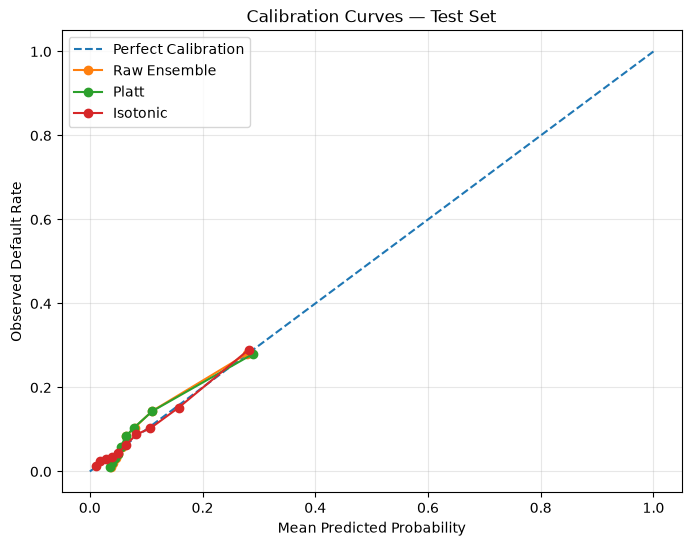

In [205]:
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect Calibration"
)

plt.plot(
    raw_pred,
    raw_true,
    marker="o",
    label="Raw Ensemble"
)

plt.plot(
    platt_pred,
    platt_true,
    marker="o",
    label="Platt"
)

plt.plot(
    isotonic_pred,
    isotonic_true,
    marker="o",
    label="Isotonic"
)

plt.xlabel(
    "Mean Predicted Probability"
)

plt.ylabel(
    "Observed Default Rate"
)

plt.title(
    "Calibration Curves — Test Set"
)

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [207]:
plt.savefig(
    "../outputs/figures/test_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

## 18. Final Calibration Selection

The raw ensemble, Platt Scaling, and Isotonic Regression were evaluated on
the held-out test set.

The Raw Ensemble and Platt Scaling produced similar discrimination, with
ROC-AUC of approximately 0.763 and PR-AUC of approximately 0.252.

Isotonic Regression produced slightly lower discrimination but achieved the
lowest Brier score:

- Raw Ensemble Brier Score: 0.0682
- Platt Brier Score: 0.0683
- Isotonic Brier Score: 0.0675

Because the downstream financial analysis uses predicted probabilities as
Probability of Default (PD), probability accuracy is particularly important.
Therefore, the Isotonic-calibrated probability is carried forward as the PD
estimate for the subsequent financial analysis.

This selection reflects a trade-off: Isotonic Regression improved the Brier
score while slightly reducing discrimination metrics.

In [214]:
pd_final = isotonic_test_prob.copy()

print(
    "Number of final PD estimates:",
    len(pd_final)
)

print(
    "Minimum PD:",
    pd_final.min()
)

print(
    "Maximum PD:",
    pd_final.max()
)

print(
    "Mean PD:",
    pd_final.mean()
)

print(
    "Observed test default rate:",
    y_test.mean()
)

Number of final PD estimates: 46127
Minimum PD: 0.0
Maximum PD: 0.8125
Mean PD: 0.08088402857465689
Observed test default rate: 0.08073362672621241


In [216]:
final_pd_output = pd.DataFrame({
    "index": X_test.index,
    "SK_ID_CURR": df.loc[
        X_test.index,
        "SK_ID_CURR"
    ].values,
    "y_true": y_test.values,
    "raw_pd": meta_test_prob,
    "platt_pd": platt_test_prob,
    "isotonic_pd": isotonic_test_prob,
    "final_pd": pd_final,
    "AMT_CREDIT": df.loc[
        X_test.index,
        "AMT_CREDIT"
    ].values
})

final_pd_output.head()

,index,SK_ID_CURR,y_true,raw_pd,platt_pd,isotonic_pd,final_pd,AMT_CREDIT
0,61065,170816,0,0.081749,0.080934,0.102881,0.102881,221832.0
1,150133,274044,0,0.079183,0.078271,0.102881,0.102881,265851.0
2,256582,396913,0,0.205995,0.212698,0.243243,0.243243,644962.5
3,248855,387891,0,0.056039,0.054453,0.065101,0.065101,592560.0
4,144968,268100,0,0.039050,0.037267,0.017792,0.017792,238500.0


In [218]:
final_pd_output.to_csv(
    "../outputs/final_pd_test.csv",
    index=False
)

print(
    "Final PD dataset saved:",
    final_pd_output.shape
)

Final PD dataset saved: (46127, 8)


In [220]:
notebook03_summary = final_test_results.copy()

notebook03_summary["Test_Default_Rate"] = (
    y_test.mean()
)

notebook03_summary.round(4)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD,Test_Default_Rate
0,Raw Ensemble,0.7627,0.2517,0.0682,0.1003,0.0810,0.0807
1,Platt,0.7627,0.2517,0.0683,0.1100,0.0809,0.0807
2,Isotonic,0.7618,0.2425,0.0675,0.0283,0.0809,0.0807


In [222]:
notebook03_summary.to_csv(
    "../outputs/calibration_test_summary.csv",
    index=False
)

print(
    "Notebook 03 summary saved."
)

Notebook 03 summary saved.


## 19. Conclusion

This notebook developed the stacking and probability-calibration components
of the credit-scoring framework.

Five-fold out-of-fold predictions were generated from Logistic Regression,
XGBoost, and a PyTorch MLP. These predictions were used as inputs to a
Meta-Logistic Regression model, allowing the three base learners to be
combined without directly training the meta-model on in-sample base-model
predictions.

The resulting ensemble was subsequently calibrated using Platt Scaling and
Isotonic Regression. Final evaluation was performed using the untouched test
set.

The Raw Ensemble and Platt Scaling achieved ROC-AUC of approximately 0.763
and PR-AUC of approximately 0.252. Isotonic Regression produced a slightly
lower ROC-AUC and PR-AUC but achieved the lowest Brier score of approximately
0.0675.

Because calibrated probability estimates are required for the downstream
Expected Loss analysis, the Isotonic-calibrated probability is carried
forward as the final PD estimate.

The next stage applies these PD estimates to scenario-based Expected Loss and
indicative risk-adjusted pricing analysis.